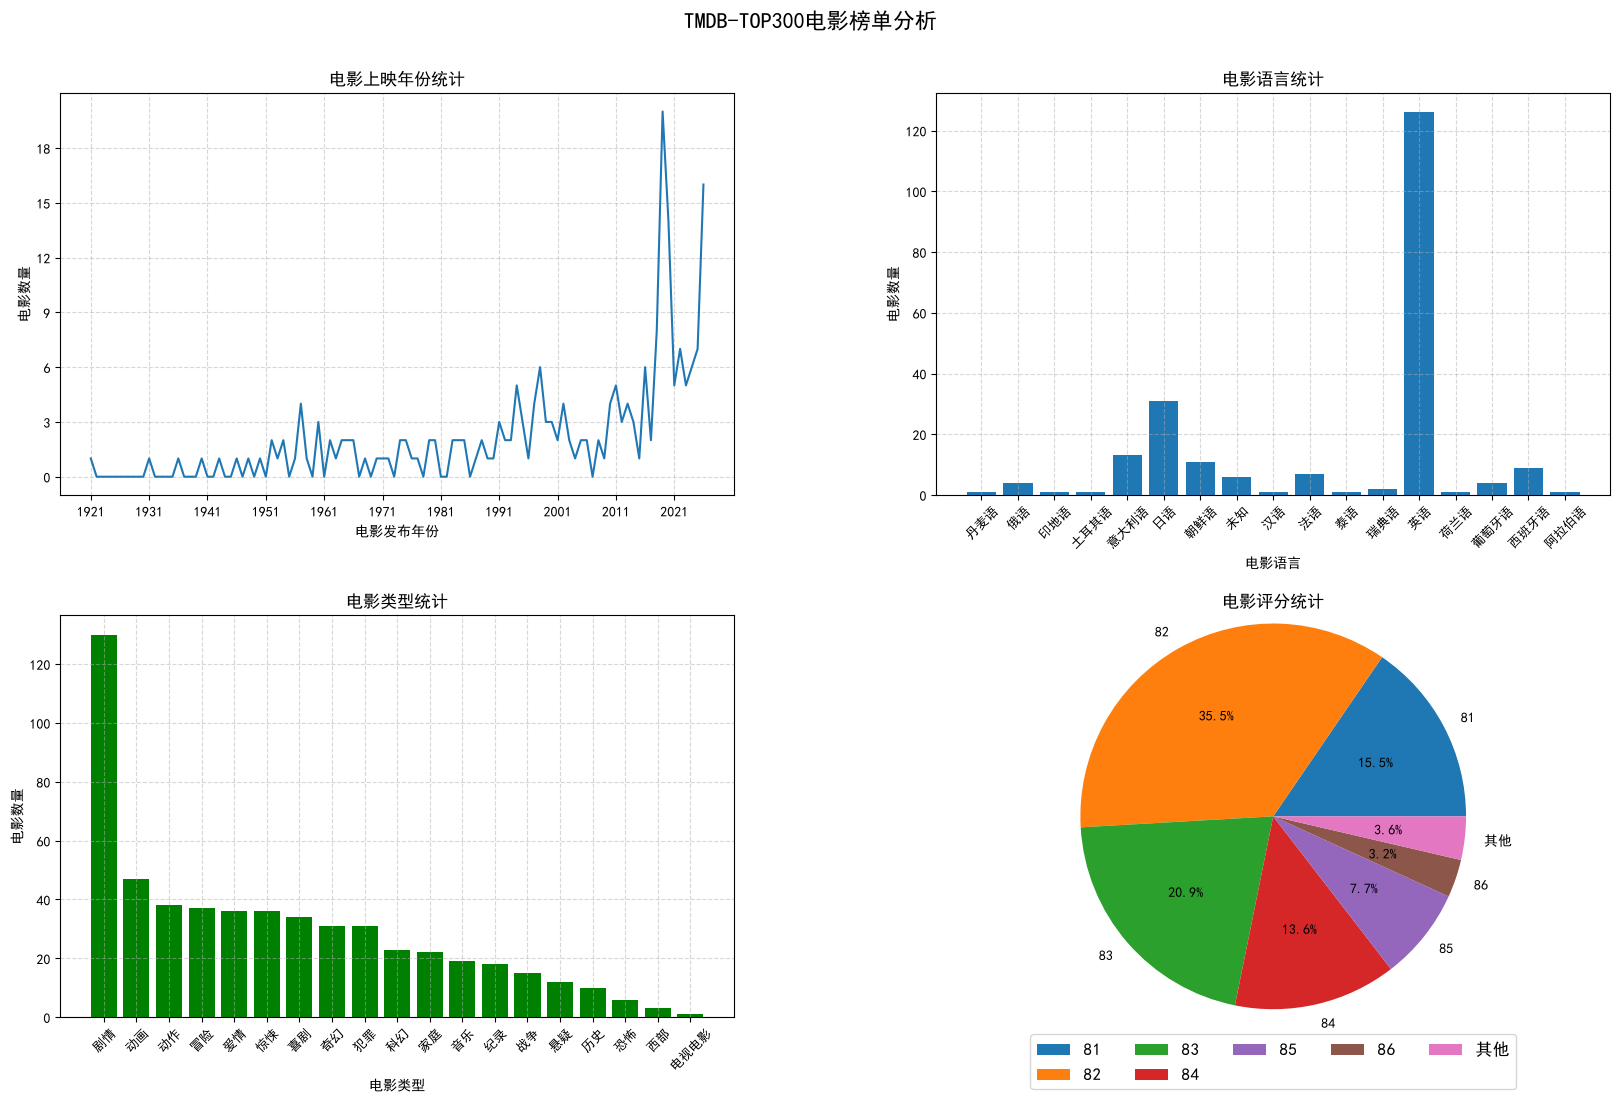

In [9]:
from re import A
from turtle import color

from matplotlib import axes, lines
from matplotlib.axes import Axes
import matplotlib.pyplot as plt
import pandas as pd


# 设置中文显示
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

#创建子图
fig,ax = plt.subplots(nrows=2,ncols=2,figsize=(20, 12),dpi=100)
fig.suptitle('TMDB-TOP300电影榜单分析',fontsize=16,x=0.5,y=0.95)

#设置子图间距
plt.subplots_adjust(wspace=0.3,hspace=0.3) #wspace:子图水平间距，hspace:子图垂直间距

# 设置子图标题
axes1:Axes=ax[0][0]
axes2:Axes=ax[0][1]
axes3:Axes=ax[1][0]
axes4:Axes=ax[1][1]

#读取文件导入数据
#int64:整形数字（不支持空值）
#Int64:整形数字（支持空值）
#float64:浮点型数字（支持空值）
#Float64:浮点型数字（支持空值）
df=pd.read_csv("./data/movie_top240.csv",usecols=['电影名','电影发布年份','电影上映时间','电影类型','电影时长','电影评分','电影语言'],
dtype={'年份':'Int64'})

#1.需求一：统计电影，每一年上映的电影数量的变化（折线图）
#1.1 缺失值处理
#df.isnull().sum() #统计每一列的缺失值数量
#1.2 数据绘图
year_count=df.groupby('电影发布年份')['电影名'].count()

#1.3 组装数据
min_year=year_count.index.min()
max_year=year_count.index.max()
x = [i for i in range(min_year,max_year+1)]
y = [int(year_count.get(i,0)) for i in x] # 如果i不存在，则返回0
# 设置y轴的值为整数
#axes1.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes1.plot(x,y)
axes1.set_title('电影上映年份统计')
axes1.set_xlabel('电影发布年份')
axes1.set_ylabel('电影数量')
axes1.set_xticks(x[::10])
y_ticks=[i for i in range(0,max(y)+1,3)]
axes1.set_yticks(y_ticks)
axes1.grid(linestyle='--',alpha=0.5)

#需求二：统计对比不同语言电影数量（柱状图）
#2.1 缺失值处理替换'-'或空值为'未知'
df['电影语言'] = df['电影语言'].replace('-', '未知')
#2.2 数据绘图
language_count=df.groupby('电影语言')['电影名'].count()
#print(language_count)
#2.3 组装数据
x=language_count.index.tolist()
y=language_count.values.tolist()
axes2.bar(x,y)
axes2.tick_params(axis='x', rotation=45, labelsize=9) # 旋转x轴标签并设置字体大小
axes2.set_title('电影语言统计')
axes2.set_xlabel('电影语言')
axes2.set_ylabel('电影数量')
axes2.grid(linestyle='--',alpha=0.5)

#需求三：统计不同类型电影数量（柱状图）
#3.1 缺失值处理
#3.2 数据绘图
genre_count=df.groupby('电影类型')['电影名'].count()
#3.3 组装数据
genre_count = (
    df['电影类型']
      .dropna()            # 1. 去掉空值，否则 split 会出错
      .str.split(',')      # 2. 按逗号切成列表：'动画,动作' -> ['动画','动作']
      .explode()           # 3. 列表“炸开”：一个类型占一行
      .str.strip()         # 4. 去掉可能的空格
      .value_counts()      # 5. 计数并降序排列
)
#print(genre_count)
x=genre_count.index.tolist()
y=genre_count.values.tolist()
axes3.bar(x,y,color='g')
axes3.tick_params(axis='x', rotation=45, labelsize=9) # 旋转x轴标签并设置字体大小
axes3.set_title('电影类型统计')
axes3.set_xlabel('电影类型')
axes3.set_ylabel('电影数量')
axes3.grid(linestyle='--',alpha=0.5)

#需求四：统计对比各个评分的电影占比（饼图）
#4.1 缺失值处理
#4.2 数据绘图
genre_count=df.groupby('电影评分')['电影名'].count()

#合并小数据---》其他
genre_count['其他']=genre_count[genre_count<5].sum()
genre_count=genre_count[genre_count>=5]
#4.3 组装数据
labels=genre_count.index.tolist()
values=genre_count.values.tolist()
axes4.pie(values,labels=labels,autopct='%1.1f%%',startangle=0,radius=1.2) #radius:饼图半径
axes4.set_title('电影评分统计')
#设置图例
#loc: 图例位置，ncol: 图例列数，bbox_to_anchor: 图例位置偏移量（0.5控制水平方位，-0.2控制垂直方位），fontsize: 图例字体大小
axes4.legend(loc='lower center',ncol=5,bbox_to_anchor=(0.5,-0.2),fontsize=12)
#axes4.grid(linestyle='--')

#保存图片
plt.savefig('./data/02.png')
plt.show() #显示图形
